# Importing Libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
df = pd.read_csv('Churn_Modelling.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Standardizing column names 

In [4]:
df = df.rename(columns=str.lower)

col_names = {
    'rownumber':'row_number',
    'customerid': 'customer_id',
    'creditscore':"credit_score",
    'numofproducts': 'num_of_products',
    'hascrcard': "credit_card",
    'isactivemember': "active_mem",
    'estimatedsalary':'salary',
    'exited':'churned'
}

df = df.rename(columns=col_names)

In [5]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# EDA

In [6]:
df.dtypes

row_number           int64
customer_id          int64
surname             object
credit_score         int64
geography           object
gender              object
age                  int64
tenure               int64
balance            float64
num_of_products      int64
credit_card          int64
active_mem           int64
salary             float64
churned              int64
dtype: object

In [7]:
df.isnull().sum()

row_number         0
customer_id        0
surname            0
credit_score       0
geography          0
gender             0
age                0
tenure             0
balance            0
num_of_products    0
credit_card        0
active_mem         0
salary             0
churned            0
dtype: int64

In [8]:
df[df.duplicated]

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned


In [9]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
df['churned'].value_counts()

churned
0    7963
1    2037
Name: count, dtype: int64

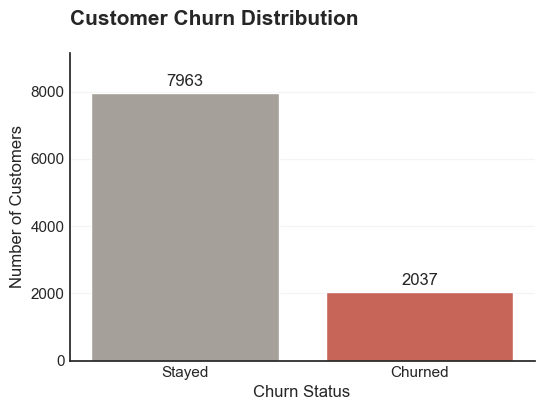

In [121]:
import seaborn as sns

sns.set_theme(style='ticks', palette='muted')

fig, ax = plt.subplots(figsize=(6,4))

churn_counts = df['churned'].value_counts().sort_index() #Couning the rows belonging to 1 and 0 

bars = ax.bar(churn_counts.index, churn_counts.values, color = ['#A6A09B', '#C86559']) # ax.bar(x, height) x is the categories 0 and 1, given by .index; height is the number of customer in each categories 

ax.set_title('Customer Churn Distribution',
             loc = 'left',
             fontsize = 15, 
             fontweight = 'bold',
             pad=20)
ax.set_xlabel('Churn Status')
ax.set_ylabel('Number of Customers')
ax.set_xticks([0,1])
ax.set_xticklabels(['Stayed', 'Churned'])
ax.bar_label(bars, padding=3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
ax.tick_params(axis='both', length = 0)
ax.set_ylim(0, churn_counts.max()*1.15)

plt.show()

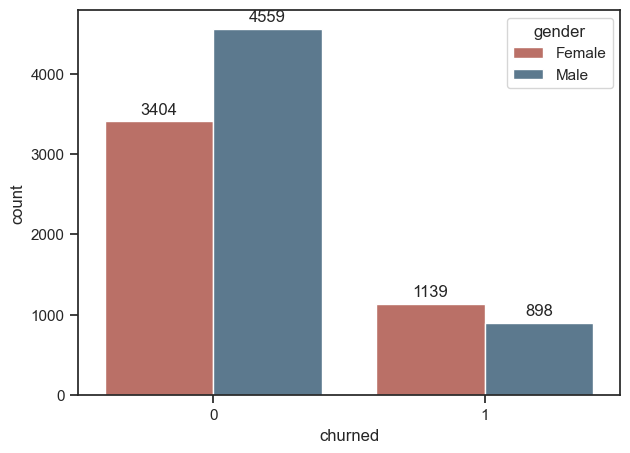

In [12]:
fig, ax = plt.subplots(figsize=(7,5))

sns.countplot(
    data = df, 
    x='churned',
    hue='gender',
    palette={'Male': '#547B96', 'Female': '#C86559'},
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.show()


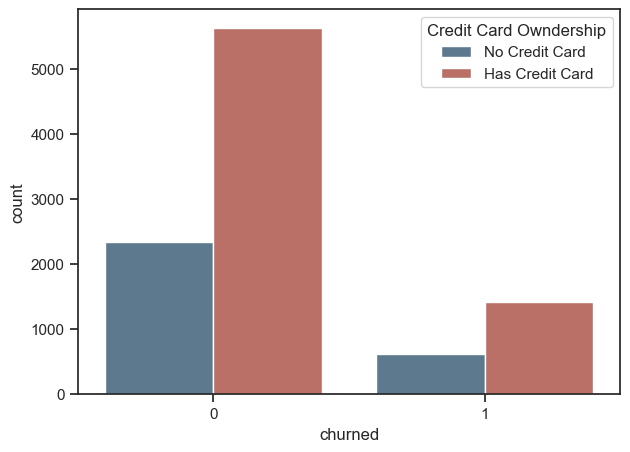

In [13]:
fig, ax = plt.subplots(figsize=(7,5))

sns.countplot(
    data=df, 
    x='churned',
    hue='credit_card',
    palette={0: '#547B96', 1: '#C86559'},
    ax=ax
)

ax.legend(
    title='Credit Card Owndership',
    labels=['No Credit Card', 'Has Credit Card']
)

plt.show()

In [14]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


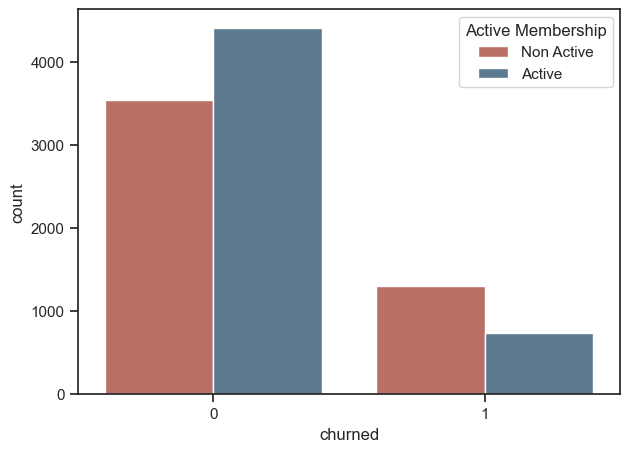

In [15]:
fig, ax = plt.subplots(figsize=(7,5))

sns.countplot(
    data=df, 
    x='churned',
    hue='active_mem',
    palette={1: '#547B96', 0: '#C86559'},
    ax=ax
)

ax.legend(
    title='Active Membership',
    labels=['Non Active', 'Active']
)

plt.show()

In [16]:
df['num_of_products'].unique()

array([1, 3, 2, 4])

In [17]:
num_of_product_churn_rate = df.groupby('num_of_products')['churned'].mean() *100

print(num_of_product_churn_rate)

num_of_products
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: churned, dtype: float64


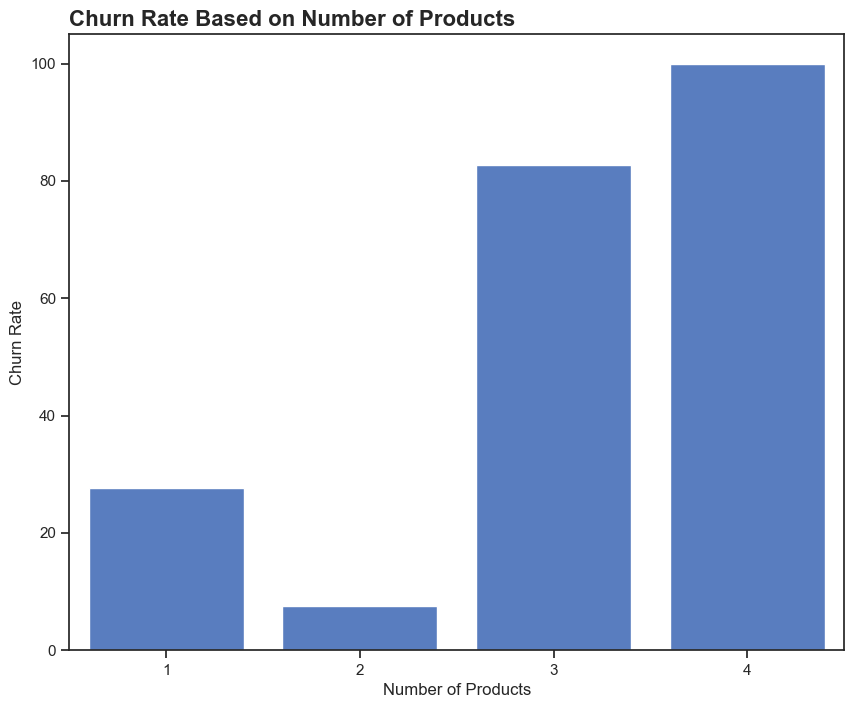

In [18]:
fig, ax = plt.subplots(figsize=(10,8))

sns.barplot(
    x=num_of_product_churn_rate.index,
    y=num_of_product_churn_rate.values,
    ax=ax
)

ax.set_title(
    'Churn Rate Based on Number of Products', 
    loc = 'left', 
    fontsize='16', 
    fontweight='bold')

ax.set_ylabel(
    'Churn Rate'
)
ax.set_xlabel('Number of Products')


plt.show()

In [19]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [20]:
df['geography'].unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [21]:
df.groupby('geography')['churned'].value_counts()

geography  churned
France     0          4204
           1           810
Germany    0          1695
           1           814
Spain      0          2064
           1           413
Name: count, dtype: int64

In [22]:
countries_churned_rate = df.groupby('geography')['churned'].mean()*100
print(countries_churned_rate)

geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: churned, dtype: float64


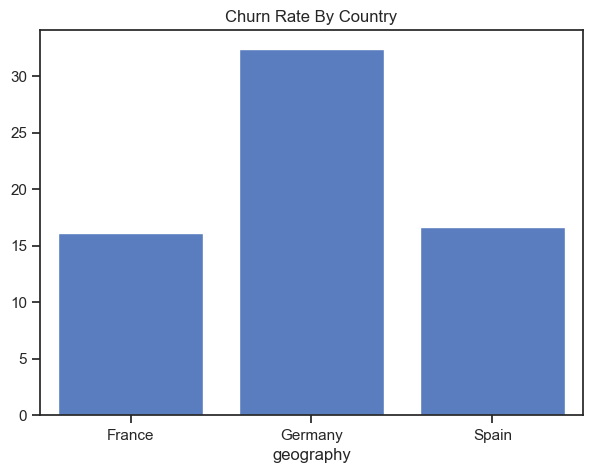

In [23]:

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=countries_churned_rate.index, 
    y=countries_churned_rate.values,
    ax=ax
)

ax.set_title('Churn Rate By Country')

plt.show()


In [24]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


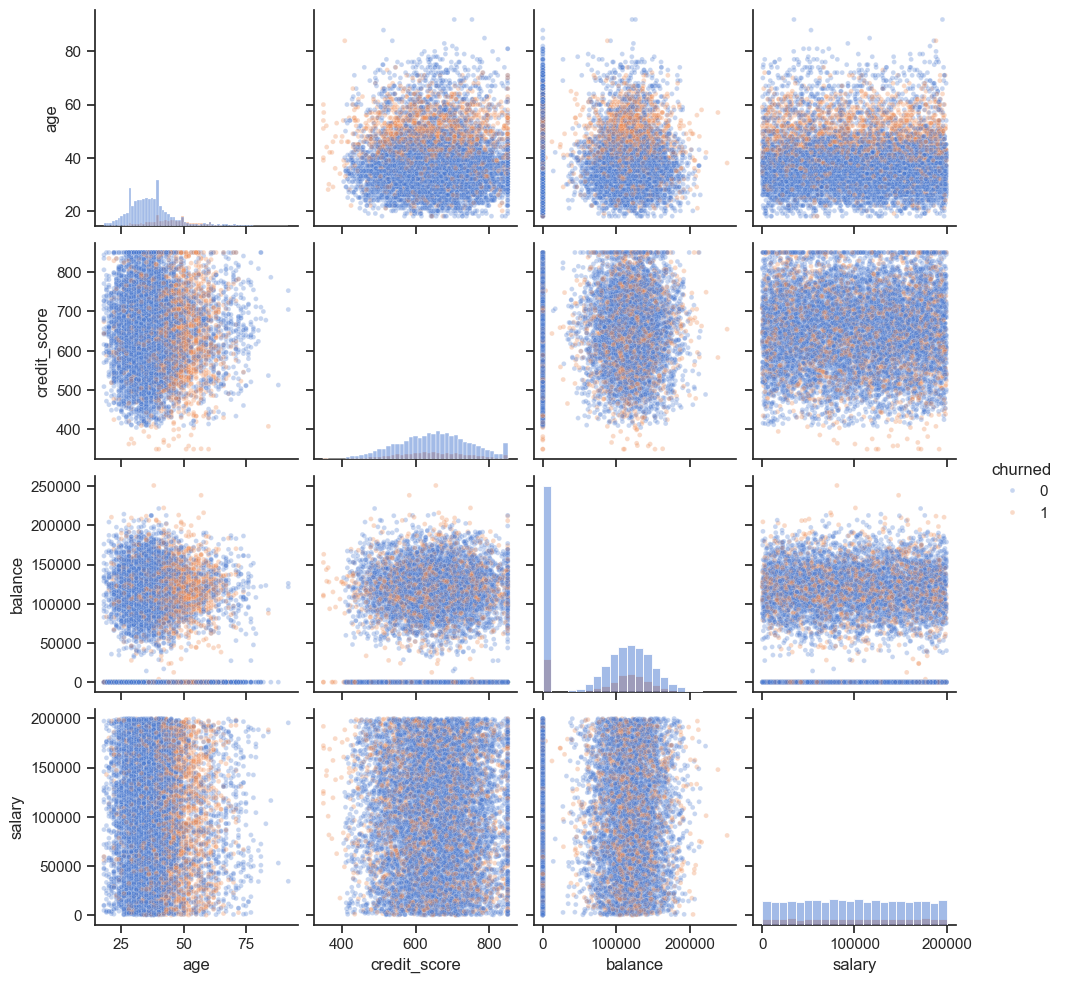

In [25]:

sns.pairplot(
    data=df, 
    vars = ['age', 'credit_score', 'balance', 'salary'], # Continous variables to compare,
    hue='churned',
    diag_kind='hist',
    plot_kws={'alpha': 0.3, 's': 12}
)


plt.show()


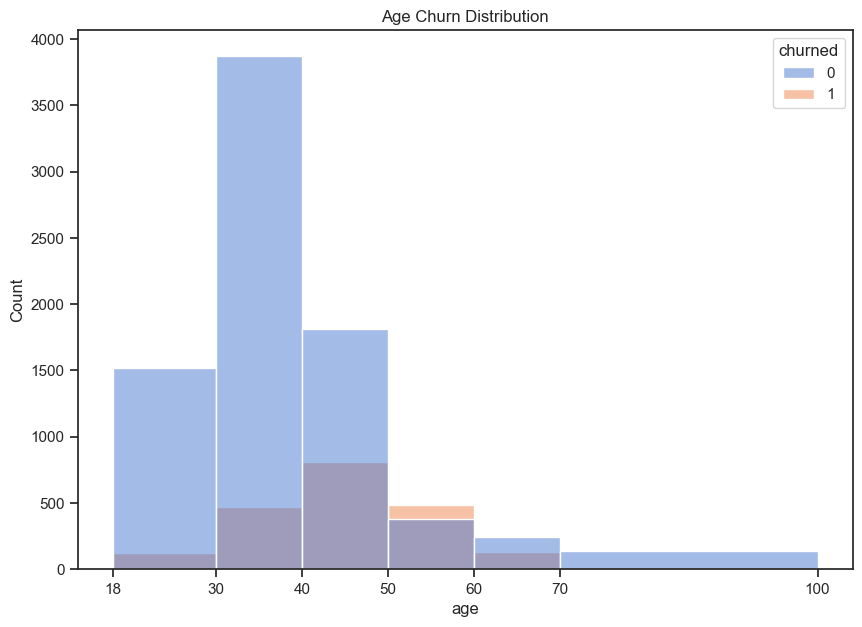

In [26]:
fig, ax = plt.subplots(figsize=(10,7))

hist_age_bins = [18, 30, 40, 50, 60, 70, 100]

sns.histplot(
    data=df, 
    x='age',
    hue='churned',
    bins=hist_age_bins, 
    multiple='layer',
    alpha=0.5,
    ax=ax
)

ax.set_title('Age Churn Distribution')
ax.set_xticks(hist_age_bins)

plt.show()

In [27]:
df['age'].max()

92

In [28]:
age_bins = [18, 30, 40, 50, 60, 70, 80, float('inf')]
age_label = ['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']

df['age_group'] = pd.cut(
    df['age'],
    bins=age_bins, 
    labels=age_label,
    right=False
)

df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned,age_group
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,40-49
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,40-49
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,40-49
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,30-39
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,40-49


In [29]:
df.groupby('age_group')['churned'].mean()*100

/var/folders/9m/d92m8dks0fb4fq5pygy1wsq40000gp/T/ipykernel_5303/2456479601.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['churned'].mean()*100


age_group
18-29     7.556368
30-39    10.883571
40-49    30.786860
50-59    56.041427
60-69    35.200000
70-79    10.294118
80+       6.666667
Name: churned, dtype: float64

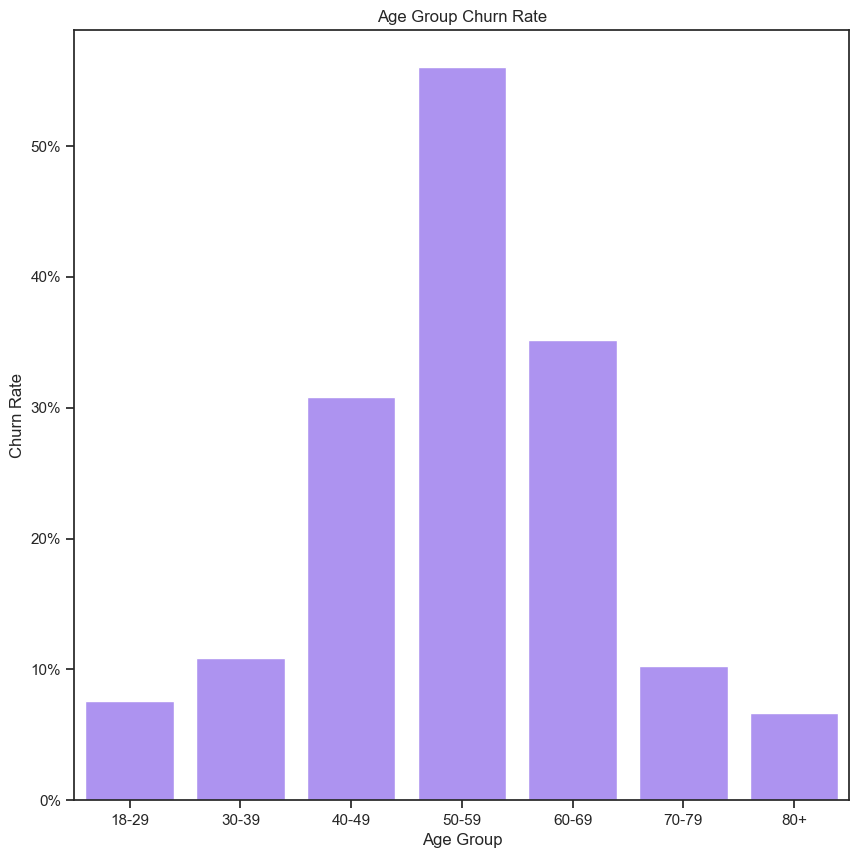

In [123]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10,10))

sns.barplot(
    data=df, 
    x='age_group',
    y='churned',
    color='#A684FF',
    errorbar=None,
    ax=ax
)

ax.set_title('Age Group Churn Rate')
ax.set_ylabel('Churn Rate')
ax.set_xlabel('Age Group')
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

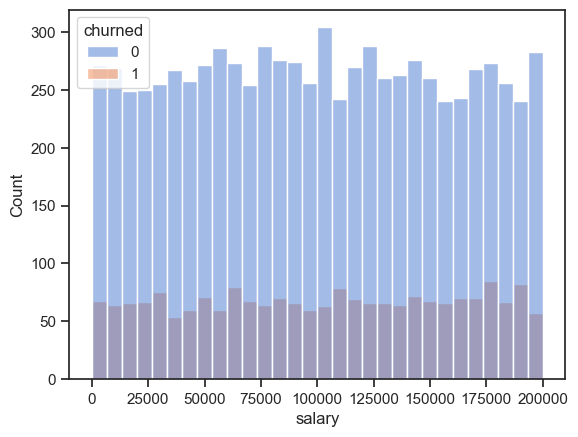

In [31]:
sns.histplot(
    data=df, 
    x='salary',
    hue='churned',
    bins=30,
    multiple='layer',
    alpha=0.5
)

plt.show()

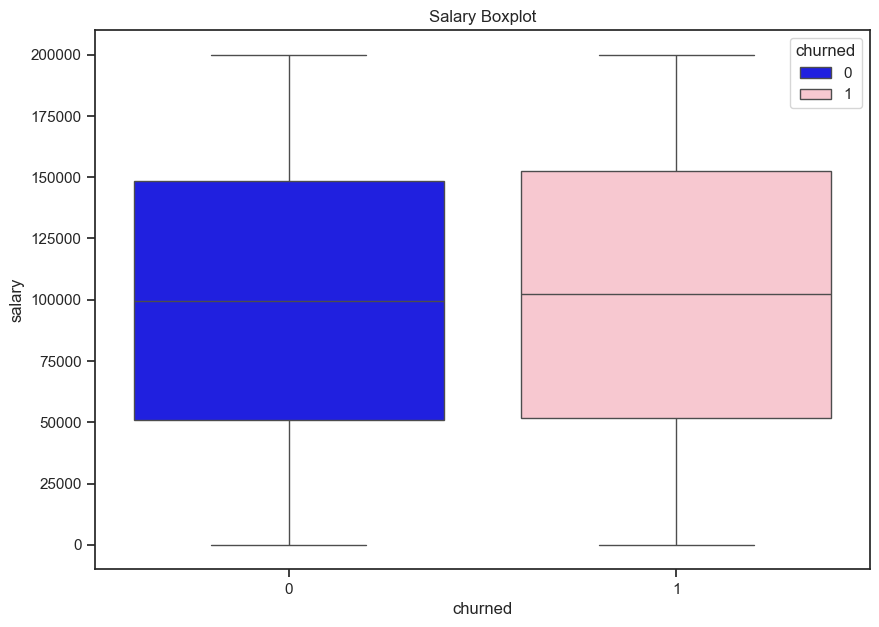

In [32]:
fig, ax = plt.subplots(figsize=(10,7))

sns.boxplot(
    data=df,
    x='churned',
    y='salary',
    hue='churned',
    palette={0: 'blue', 1:'pink'},
    ax=ax
)

ax.set_title('Salary Boxplot')

plt.show()

In [33]:
credit_bins = [300, 500, 600, 700, 800, 851]
credit_labels=['300-499', '500-599', '600-699', '700-799', '800-850']

df['credit_score_bins'] = pd.cut(
    df['credit_score'],
    bins=credit_bins,
    labels=credit_labels,
    right=False
)

df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned,age_group,credit_score_bins
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,40-49,600-699
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,40-49,600-699
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,40-49,500-599
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,30-39,600-699
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,40-49,800-850


In [34]:
df.groupby('credit_score_bins')['churned'].mean()*100

/var/folders/9m/d92m8dks0fb4fq5pygy1wsq40000gp/T/ipykernel_5303/4030960191.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('credit_score_bins')['churned'].mean()*100


credit_score_bins
300-499    23.734177
500-599    21.232306
600-699    19.722368
700-799    19.895708
800-850    19.541985
Name: churned, dtype: float64

/var/folders/9m/d92m8dks0fb4fq5pygy1wsq40000gp/T/ipykernel_5303/3494422828.py:3: UserWarning: The palette list has more values (7) than needed (5), which may not be intended.
  sns.barplot(


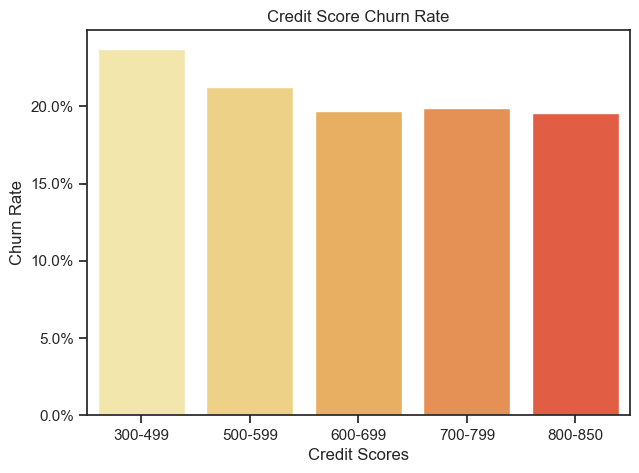

In [35]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=df,
    x='credit_score_bins',
    y='churned',
    hue='credit_score_bins',
    palette=sns.color_palette('YlOrRd', n_colors=len(age_label)),
    legend=False,
    errorbar=None,
    ax=ax
)

ax.set_title('Credit Score Churn Rate')
ax.set_ylabel('Churn Rate')
ax.set_xlabel('Credit Scores')
ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.show()

In [36]:
df.head()

,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned,age_group,credit_score_bins
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,40-49,600-699
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,40-49,600-699
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,40-49,500-599
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,30-39,600-699
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,40-49,800-850


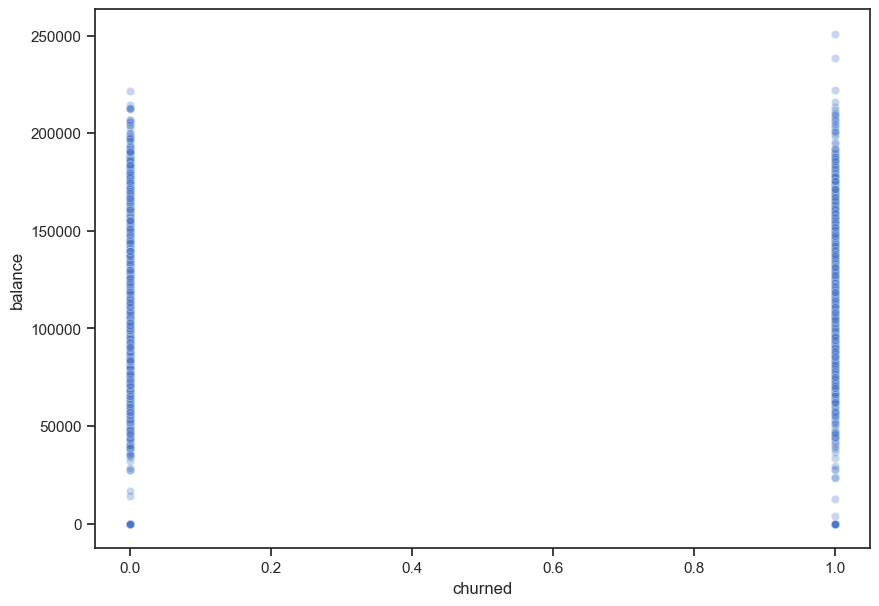

In [37]:
fig, ax = plt.subplots(figsize=(10,7))

sns.scatterplot(
    data=df,
    x='churned',
    y='balance',
    alpha = 0.3,
    ax=ax
)

plt.show()

# Model

In [38]:
label_encoder = LabelEncoder() #turning categorical texts into numerical integers (0,1)
df['gender'] = label_encoder.fit_transform(df['gender']) #fit is saying to learn the transformation rule (label encoder) of the column and transform is saying to apply those rules to the column
df = pd.get_dummies(df, columns=['geography'], drop_first=True) # dummies are converting multi level categories into 0/1 and drop_firt=true ensures there are n-1 dummies to avoid multicollinearity. 

In [39]:
df.head()

,row_number,customer_id,surname,credit_score,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned,age_group,credit_score_bins,geography_Germany,geography_Spain
0,1,15634602,Hargrave,619,0,42,2,0.00,1,1,1,101348.88,1,40-49,600-699,False,False
1,2,15647311,Hill,608,0,41,1,83807.86,1,0,1,112542.58,0,40-49,600-699,False,True
2,3,15619304,Onio,502,0,42,8,159660.80,3,1,0,113931.57,1,40-49,500-599,False,False
3,4,15701354,Boni,699,0,39,1,0.00,2,0,0,93826.63,0,30-39,600-699,False,False
4,5,15737888,Mitchell,850,0,43,2,125510.82,1,1,1,79084.10,0,40-49,800-850,False,True


df.columns

In [40]:
features = [ 'credit_score', 'gender', 'age',
       'tenure', 'balance', 'num_of_products', 'credit_card', 'active_mem',
       'salary', 'geography_Germany', 'geography_Spain']

X = df[features]
y = df['churned']

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [43]:
X_train[:5]

array([[ 0.35649971,  0.91324755, -0.6557859 ,  0.34567966, -1.21847056,
         0.80843615,  0.64920267,  0.97481699,  1.36766974, -0.57946723,
        -0.57638802],
       [-0.20389777,  0.91324755,  0.29493847, -0.3483691 ,  0.69683765,
         0.80843615,  0.64920267,  0.97481699,  1.6612541 ,  1.72572313,
        -0.57638802],
       [-0.96147213,  0.91324755, -1.41636539, -0.69539349,  0.61862909,
        -0.91668767,  0.64920267, -1.02583358, -0.25280688, -0.57946723,
         1.73494238],
       [-0.94071667, -1.09499335, -1.13114808,  1.38675281,  0.95321202,
        -0.91668767,  0.64920267, -1.02583358,  0.91539272, -0.57946723,
        -0.57638802],
       [-1.39733684,  0.91324755,  1.62595257,  1.38675281,  1.05744869,
        -0.91668767, -1.54035103, -1.02583358, -1.05960019, -0.57946723,
        -0.57638802]])

# Random Forest Classifier Model 

In [44]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [45]:
y_pred = model.predict(X_test)

In [46]:
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

In [47]:
print(conf_matrix)
print(class_report)
print(accuracy)

[[1550   57]
 [ 207  186]]
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.77      0.47      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.86      2000

0.868


In [48]:
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
names = [features[i].replace('_', ' ').title() for i in indices]


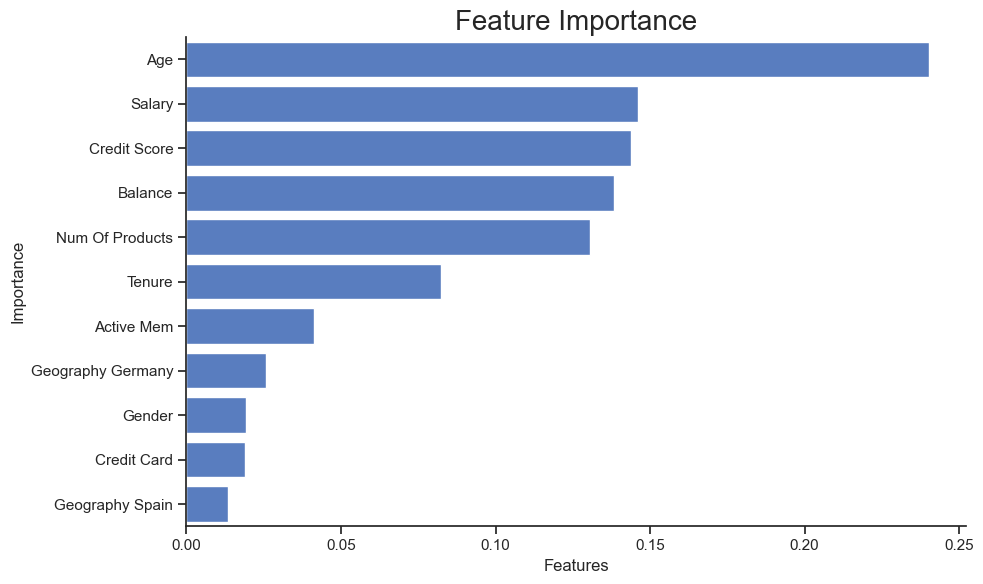

In [49]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.set_theme(style='whitegrid')

sns.barplot(
    x=importances[indices],
    y = names,
    ax=ax
)

ax.set_title('Feature Importance', fontsize = 20, pad= 5)
ax.set_xlabel('Features')
ax.set_ylabel('Importance')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Logistic Regression

In [50]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

y_pred_log_reg = log_reg.predict(X_test)

conf_matrix_log_reg = confusion_matrix(y_test, y_pred_log_reg)
class_report_log_reg = classification_report(y_test, y_pred_log_reg)
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)

print(conf_matrix_log_reg, class_report_log_reg, accuracy_log_reg)

[[1541   66]
 [ 313   80]]               precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.55      0.20      0.30       393

    accuracy                           0.81      2000
   macro avg       0.69      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000
 0.8105


# Support Vector Machine

In [53]:
from sklearn.svm import SVC
from sklearn.metrics import precision_score

svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)
class_report_svm = classification_report(y_test, y_pred_svm)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

precision = precision_score(y_test, y_pred_svm, average='macro', zero_division=0)

print(conf_matrix_svm, class_report_svm, accuracy_svm)
print('precision:', precision)

[[1607    0]
 [ 393    0]]               precision    recall  f1-score   support

           0       0.80      1.00      0.89      1607
           1       0.00      0.00      0.00       393

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.80      0.72      2000
 0.8035
precision: 0.40175


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


# KNN Model

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
class_report_knn = classification_report(y_test, y_pred_knn)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(conf_matrix_knn, class_report_knn, accuracy_knn)

In [55]:

print(conf_matrix_knn, class_report_knn, accuracy_knn)

[[1508   99]
 [ 251  142]]               precision    recall  f1-score   support

           0       0.86      0.94      0.90      1607
           1       0.59      0.36      0.45       393

    accuracy                           0.82      2000
   macro avg       0.72      0.65      0.67      2000
weighted avg       0.80      0.82      0.81      2000
 0.825


# Gradient Boosting Model

In [56]:
from sklearn.ensemble import GradientBoostingClassifier

gbm_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gbm_model.fit(X_train, y_train)

y_pred_gbm = gbm_model.predict(X_test)

conf_matrix_gbm = confusion_matrix(y_test, y_pred_gbm)
class_report_gbm = classification_report(y_test, y_pred_gbm)
accuracy_gbm = accuracy_score(y_test, y_pred_gbm)

print(conf_matrix_gbm, class_report_gbm, accuracy_gbm)

[[1542   65]
 [ 202  191]]               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.75      0.49      0.59       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.86      2000
 0.8665


In [57]:
df.head()

,row_number,customer_id,surname,credit_score,gender,age,tenure,balance,num_of_products,credit_card,active_mem,salary,churned,age_group,credit_score_bins,geography_Germany,geography_Spain
0,1,15634602,Hargrave,619,0,42,2,0.00,1,1,1,101348.88,1,40-49,600-699,False,False
1,2,15647311,Hill,608,0,41,1,83807.86,1,0,1,112542.58,0,40-49,600-699,False,True
2,3,15619304,Onio,502,0,42,8,159660.80,3,1,0,113931.57,1,40-49,500-599,False,False
3,4,15701354,Boni,699,0,39,1,0.00,2,0,0,93826.63,0,30-39,600-699,False,False
4,5,15737888,Mitchell,850,0,43,2,125510.82,1,1,1,79084.10,0,40-49,800-850,False,True


# Campagin Benefit Analysis

Would a campaign that targets churning customer benefit the bank? 

Assumptions:
- Cost of campaign per customer: 20 monetary units
- Campagin effectiveness: 30% of true positives can be persuaded to stay 
- Value of retained customer: 500 monetary units 

Set up:
- Campaing targets all predicted churners (TP and FP)
- Cost of campaign is (TP + FP) * cost (20) of campaign per customer
- Campaign effectivenss is 30% of TP, as it would only apply to those customers who are actually going to churn 
- Value of retained customer is (30% * TP) * value (500) of retained customer 
- Benefit of campagin is Value retained - Cost of campaign 

## Random Forest Analysis

In [107]:
conf_matrices = {
    'rf': conf_matrix, 
    'lr' : conf_matrix_log_reg,
    'knn' : conf_matrix_knn,
    'svm' : conf_matrix_svm,
    'gbm' : conf_matrix_gbm
}

model_names = {
    'rf' : 'Random Forest',
    'lr' : 'Logistic Regression',
    'knn' : 'K-Nearest Neighbors',
    'svm': 'Support Vector Machine',
    'gbm' : 'Gradient Bossting'
}


def campaign_benefit_analysis(matrices): 
    results = []

    for model, cm in matrices.items():
        TP = cm[1,1]
        targets = TP + cm[0,1]
        
        campaign_cost = targets * 20
        campaign_effect = TP * 0.30 
        value_customer = campaign_effect * 500
        campaign_benefit = value_customer - campaign_cost

        results.append({
            'Model' : model_names[model], 
            'Campaign Benefit': campaign_benefit,
            'TP' : TP,
            'FP' : targets - TP,
            'Campaign Target' : targets,
            'Campaign Cost' : campaign_cost,
            'Customers Retained' : campaign_effect
        })

    campaign_df = pd.DataFrame(results).style.format({
    'Campaign Benefit': '${:,.2f}',
    'Campaign Cost': '${:,.2f}',
    'Customers Retained': '{:,.1f}',
    'TP': '{:,.0f}',
    'FP': '{:,.0f}',
    'Campaign Target': '{:,.0f}'
    }).data 


    return campaign_df 


campaign_df = campaign_benefit_analysis(conf_matrices)
campaign_df 

    

,Model,Campaign Benefit,TP,FP,Campaign Target,Campaign Cost,Customers Retained
0,Random Forest,23040.0,186,57,243,4860,55.8
1,Logistic Regression,9080.0,80,66,146,2920,24.0
2,K-Nearest Neighbors,16480.0,142,99,241,4820,42.6
3,Support Vector Machine,0.0,0,0,0,0,0.0
4,Gradient Bossting,23530.0,191,65,256,5120,57.3


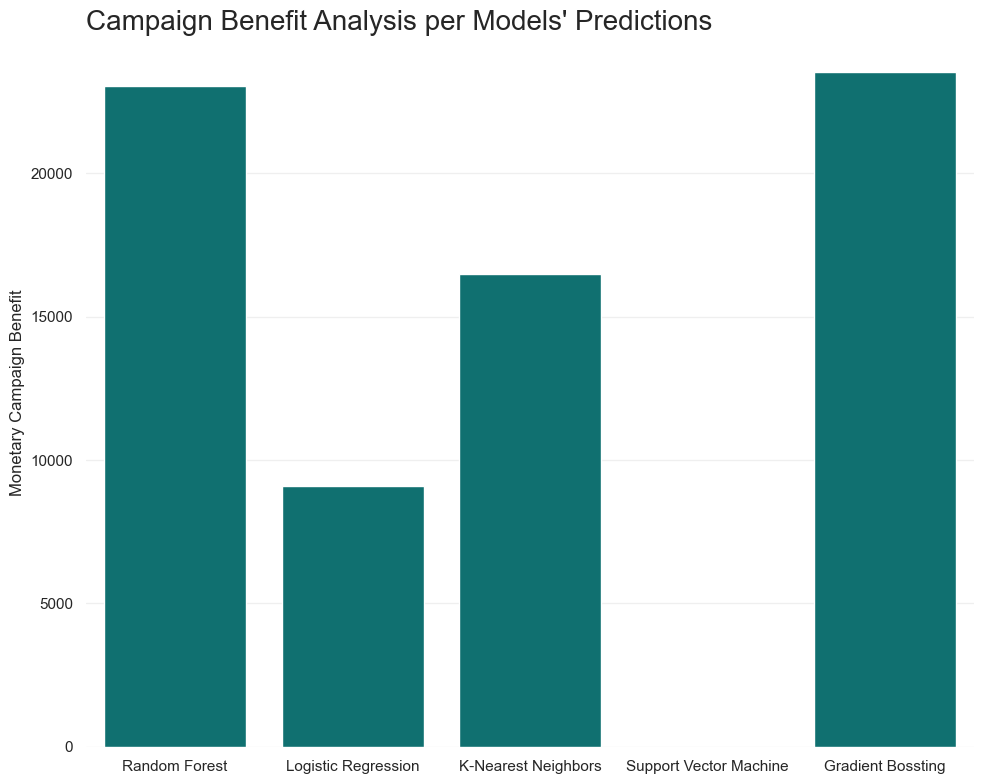

In [127]:
sns.set_theme(style='whitegrid', context='notebook')

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    data=campaign_df,
    x = 'Model', 
    y = 'Campaign Benefit',
    color = '#008080',
    ax = ax
)

ax.set_title("Campaign Benefit Analysis per Models' Predictions", fontsize=20, loc = 'left')
ax.set_xlabel(None)
ax.set_ylabel('Monetary Campaign Benefit')

ax.grid(axis='x', visible=False)
ax.grid(axis='y', alpha = 0.3)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()